<h1 style="color:#c2185b; text-align:center; font-family:Arial;">Employee Attrition Prediction System</h1>

# 1.Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


# 2.Load the Dataset

In [4]:
file_path = r"C:\Users\Swarda\Desktop\employee_attrition_cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (10000, 14)


,Employee_ID,Age,Department,Job_Role,Monthly_Income,Year_At_Company,Job_Satisfaction,Work_Hours,Overtime,Distance_From_Home,Training_Hours,Performance_Rating,Pervious_Compaines,Attrition
0,EP001,25.0,Sales,Sales Executive,32000.0,2.0,3.0,8.0,Yes,12.0,20.0,3.0,2.0,Yes
1,EP002,32.0,IT,Software Developer,58000.0,5.0,4.0,9.0,No,8.0,35.0,4.0,1.0,No
2,EP003,28.0,Sales,HR Executive,41000.0,3.0,2.0,8.0,Yes,18.0,25.0,3.0,3.0,Yes
3,EP004,35.0,Finance,Financial Analyst,62000.0,7.0,4.0,8.0,No,6.0,40.0,4.0,2.0,No
4,EP005,24.0,IT,Junior Developer,35000.0,1.0,2.0,10.0,Yes,22.0,15.0,3.0,1.0,No


# 3.Check The Dataset

In [5]:
print("First 5 records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())



First 5 records:


,Employee_ID,Age,Department,Job_Role,Monthly_Income,Year_At_Company,Job_Satisfaction,Work_Hours,Overtime,Distance_From_Home,Training_Hours,Performance_Rating,Pervious_Compaines,Attrition
0,EP001,25.0,Sales,Sales Executive,32000.0,2.0,3.0,8.0,Yes,12.0,20.0,3.0,2.0,Yes
1,EP002,32.0,IT,Software Developer,58000.0,5.0,4.0,9.0,No,8.0,35.0,4.0,1.0,No
2,EP003,28.0,Sales,HR Executive,41000.0,3.0,2.0,8.0,Yes,18.0,25.0,3.0,3.0,Yes
3,EP004,35.0,Finance,Financial Analyst,62000.0,7.0,4.0,8.0,No,6.0,40.0,4.0,2.0,No
4,EP005,24.0,IT,Junior Developer,35000.0,1.0,2.0,10.0,Yes,22.0,15.0,3.0,1.0,No



Column names:
['Employee_ID', 'Age', 'Department', 'Job_Role', 'Monthly_Income', 'Year_At_Company', 'Job_Satisfaction', 'Work_Hours', 'Overtime', 'Distance_From_Home', 'Training_Hours', 'Performance_Rating', 'Pervious_Compaines', 'Attrition']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee_ID         10000 non-null  str    
 1   Age                 10000 non-null  float64
 2   Department          10000 non-null  str    
 3   Job_Role            10000 non-null  str    
 4   Monthly_Income      10000 non-null  float64
 5   Year_At_Company     10000 non-null  float64
 6   Job_Satisfaction    10000 non-null  float64
 7   Work_Hours          10000 non-null  float64
 8   Overtime            10000 non-null  str    
 9   Distance_From_Home  10000 non-null  float64
 10  Training_Hours      10000 non-null  float64


# 4. Clean the Data

In [6]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Check whether the target column exists
if "Attrition" not in df.columns:
    raise ValueError("The dataset must contain an 'Attrition' column.")

# Standardize the target values
df["Attrition"] = df["Attrition"].astype("string").str.strip().str.title()

# Keep only valid target labels
df = df[df["Attrition"].isin(["Yes", "No"])].copy()

print("Cleaned dataset shape:", df.shape)
print("\nAttrition counts:")
print(df["Attrition"].value_counts())

Cleaned dataset shape: (10000, 14)

Attrition counts:
Attrition
No     5019
Yes    4981
Name: count, dtype: int64[pyarrow]


# 5.Visualizations

# 5.1 Attrition Distribution

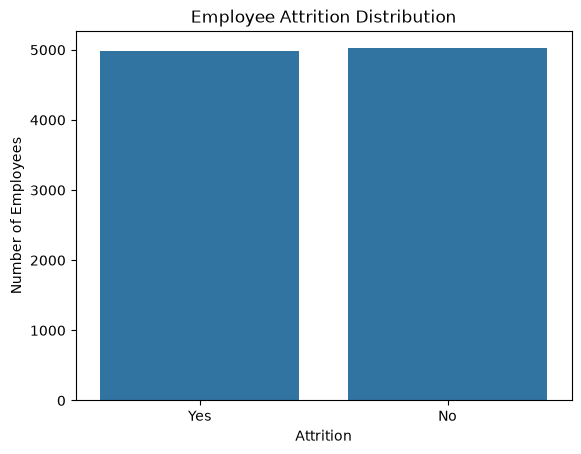

In [20]:
sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

# 5.2 Attrition by department

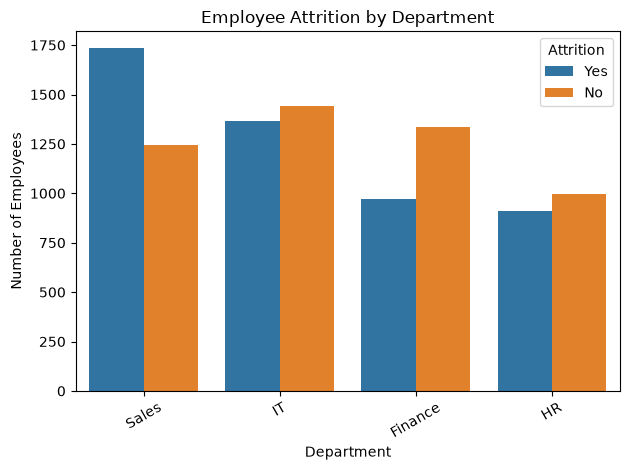

In [21]:
if "Department" in df.columns:
    sns.countplot(data=df, x="Department", hue="Attrition")
    plt.title("Employee Attrition by Department")
    plt.xlabel("Department")
    plt.ylabel("Number of Employees")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("Department column is not available.")

# 5.3 Attrition Percentage

Attrition Percentage:
Attrition
No     50.19
Yes    49.81
Name: proportion, dtype: Float64


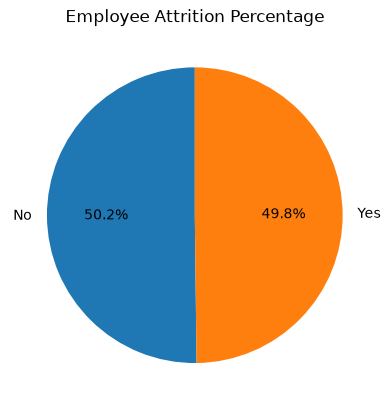

In [30]:
attrition_percent = df["Attrition"].value_counts(normalize=True) * 100

print("Attrition Percentage:")
print(attrition_percent.round(2))

attrition_percent.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Employee Attrition Percentage")
plt.ylabel("")
plt.show()

# 5.4 Attrition and overtime

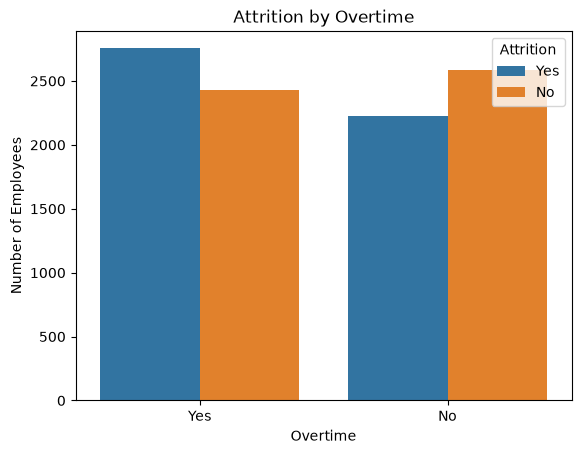

In [22]:
if "Overtime" in df.columns:
    sns.countplot(data=df, x="Overtime", hue="Attrition")
    plt.title("Attrition by Overtime")
    plt.xlabel("Overtime")
    plt.ylabel("Number of Employees")
    plt.show()
else:
    print("Overtime column is not available.")

# 5.6 Montly income and attrition

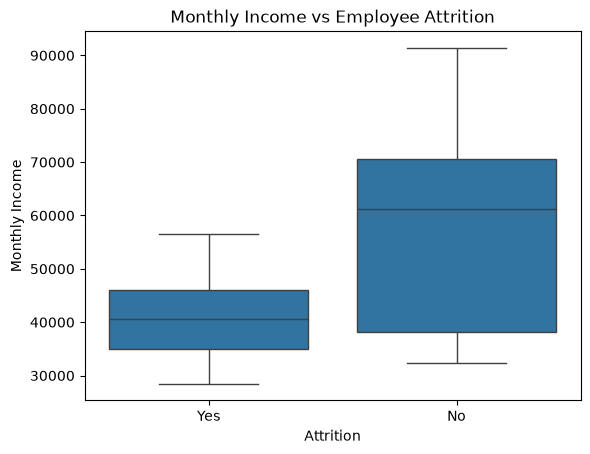

In [23]:
if "Monthly_Income" in df.columns:
    sns.boxplot(data=df, x="Attrition", y="Monthly_Income",showfliers=False)
    plt.title("Monthly Income vs Employee Attrition")
    plt.xlabel("Attrition")
    plt.ylabel("Monthly Income")
    plt.show()
else:
    print("Monthly_Income column is not available.")

# 5.7 Years at company and attrition


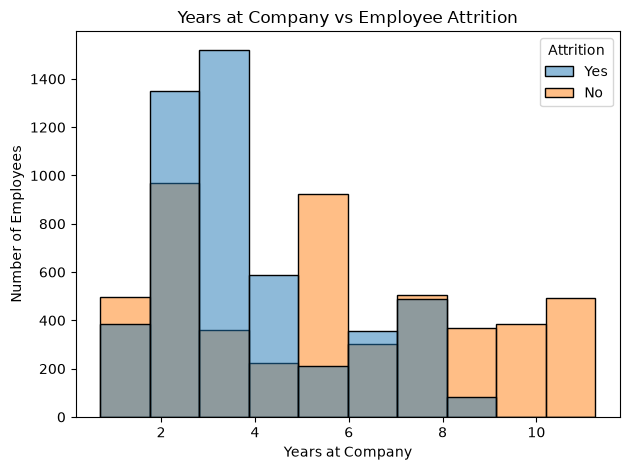

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(
    data=df,
    x="Year_At_Company",
    hue="Attrition",
    bins=10,
    multiple="layer",
    kde=False
)

plt.title("Years at Company vs Employee Attrition")
plt.xlabel("Years at Company")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

# 6.Split the dataset

In [8]:

# 6. Split the Dataset

from sklearn.model_selection import train_test_split

# Remove duplicate rows and prepare features
df = df.drop_duplicates().copy()
df.columns = df.columns.str.strip()

# Input features: exclude target and employee ID
X = df.drop(columns=["Attrition", "Employee_ID"], errors="ignore")

# Target variable: No = 0, Yes = 1
y = df["Attrition"].astype(str).str.strip().str.title().map(
    {"No": 0, "Yes": 1}
)

# Remove rows with invalid target values, if any
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].astype(int)

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Input features:", X.columns.tolist())
print("Target values: 0 = No Attrition, 1 = Attrition")


Training records: 8000
Testing records: 2000
Input features: ['Age', 'Department', 'Job_Role', 'Monthly_Income', 'Year_At_Company', 'Job_Satisfaction', 'Work_Hours', 'Overtime', 'Distance_From_Home', 'Training_Hours', 'Performance_Rating', 'Pervious_Compaines']
Target values: 0 = No Attrition, 1 = Attrition


# 7.Train the Random Forest Model

In [9]:

# 7. Train the Random Forest Model

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Preprocessing for numeric columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Create the complete model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


# 8. Evaluate the model

In [10]:

# 8. Evaluate the Random Forest Model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict test results
y_pred = model.predict(X_test)

# Predict probability of employee attrition (class 1)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# ROC-AUC requires both classes in the test set
if len(set(y_test)) == 2:
    roc_auc = roc_auc_score(y_test, y_prob)
else:
    roc_auc = float("nan")

# Display results
print("=" * 40)
print("MODEL EVALUATION RESULTS")
print("=" * 40)

print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No Attrition", "Attrition"],
    zero_division=0
))


MODEL EVALUATION RESULTS
Accuracy  : 1.0000 (100.00%)
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000

Classification Report:
              precision    recall  f1-score   support

No Attrition       1.00      1.00      1.00      1004
   Attrition       1.00      1.00      1.00       996

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



# 9.Prediction for employees

In [11]:

# 9. Prediction for an Example Employee

# Create an example using the same columns as training data
new_employee = X.iloc[[0]].copy()

# Example employee details
example_values = {
    "Age": 28,
    "Department": "IT",
    "Job_Role": "Software Developer",
    "Monthly_Income": 45000,
    "Year_At_Company": 2,
    "Job_Satisfaction": 2,
    "Work_Hours": 9,
    "Overtime": "Yes",
    "Distance_From_Home": 10,
    "Training_Hours": 25,
    "Performance_Rating": 3,
    "Pervious_Compaines": 2
}

# Update only columns that exist in the dataset
for column, value in example_values.items():
    if column in new_employee.columns:
        new_employee.loc[:, column] = value

# Predict employee attrition
prediction = model.predict(new_employee)[0]
probability = model.predict_proba(new_employee)[0, 1]

print("=" * 45)
print("EXAMPLE EMPLOYEE DETAILS")
print("=" * 45)
display(new_employee)

print("\nPREDICTION RESULT")
print("-" * 45)

if prediction == 1:
    print("Prediction: Employee may leave the company.")
else:
    print("Prediction: Employee may stay in the company.")

print(f"Estimated attrition probability: {probability * 100:.2f}%")
print("=" * 45)


EXAMPLE EMPLOYEE DETAILS


,Age,Department,Job_Role,Monthly_Income,Year_At_Company,Job_Satisfaction,Work_Hours,Overtime,Distance_From_Home,Training_Hours,Performance_Rating,Pervious_Compaines
0,28.0,IT,Software Developer,45000.0,2.0,2.0,9.0,Yes,10.0,25.0,3.0,2.0



PREDICTION RESULT
---------------------------------------------
Prediction: Employee may stay in the company.
Estimated attrition probability: 42.00%


# 10.New Employee Prediction

In [12]:

# 10. New Employee Prediction Using User Input

print("=" * 50)
print(" EMPLOYEE ATTRITION PREDICTION SYSTEM")
print("=" * 50)

# Take employee details from the user
age = float(input("Enter employee age: "))
department = input("Enter department (IT, HR, Sales, Finance): ").strip()
job_role = input("Enter job role: ").strip()
monthly_income = float(input("Enter monthly income: "))
years_at_company = float(input("Enter years at company: "))
job_satisfaction = float(input("Enter job satisfaction (1-4): "))
work_hours = float(input("Enter work hours per day: "))
overtime = input("Does employee work overtime? (Yes/No): ").strip().title()


# Create employee details using exact dataset column names
employee_data = {
    "Age": age,
    "Department": department,
    "Job_Role": job_role,
    "Monthly_Income": monthly_income,
    "Year_At_Company": years_at_company,
    "Job_Satisfaction": job_satisfaction,
    "Work_Hours": work_hours,
    "Overtime": overtime,
    
}

# Create DataFrame with the exact training feature order
new_employee = pd.DataFrame([employee_data])
new_employee = new_employee.reindex(columns=X.columns)

# Predict attrition
prediction = model.predict(new_employee)[0]
probability = model.predict_proba(new_employee)[0, 1]

# Display employee details
print("\n" + "=" * 50)
print("EMPLOYEE DETAILS")
print("=" * 50)
display(new_employee)

# Display prediction
print("\n" + "=" * 50)
print("PREDICTION RESULT")
print("=" * 50)

if prediction == 1:
    print("Prediction: Employee may leave the company.")
else:
    print("Prediction: Employee may stay in the company.")

print(f"Estimated attrition probability: {probability * 100:.2f}%")
print("=" * 50)


 EMPLOYEE ATTRITION PREDICTION SYSTEM


Enter employee age:  24
Enter department (IT, HR, Sales, Finance):  it
Enter job role:  java developer
Enter monthly income:  100000
Enter years at company:  10
Enter job satisfaction (1-4):  3
Enter work hours per day:  12
Does employee work overtime? (Yes/No):  yes



EMPLOYEE DETAILS


,Age,Department,Job_Role,Monthly_Income,Year_At_Company,Job_Satisfaction,Work_Hours,Overtime,Distance_From_Home,Training_Hours,Performance_Rating,Pervious_Compaines
0,24.0,it,java developer,100000.0,10.0,3.0,12.0,Yes,NaN,NaN,NaN,NaN



PREDICTION RESULT
Prediction: Employee may stay in the company.
Estimated attrition probability: 36.00%


# 11.Model Summary

In [11]:
print("=" * 45)
print("EMPLOYEE ATTRITION PREDICTION SYSTEM")
print("=" * 45)

print("Algorithm: Random Forest Classifier")
print(f"Training records: {len(X_train)}")
print(f"Testing records: {len(X_test)}")
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

print("=" * 45)
print("Project completed successfully!")

EMPLOYEE ATTRITION PREDICTION SYSTEM
Algorithm: Random Forest Classifier
Training records: 8000
Testing records: 2000
Accuracy: 100.00%
Precision: 1.0000
Recall: 1.0000
F1-Score: 1.0000
Project completed successfully!


# Dashboard !!

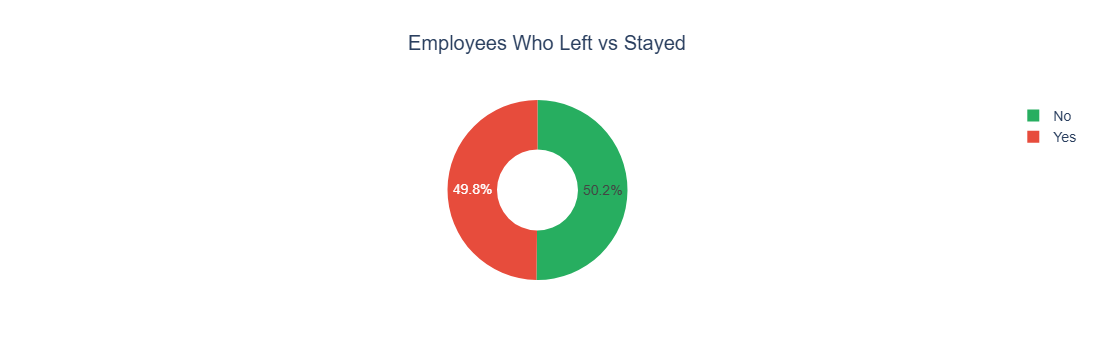

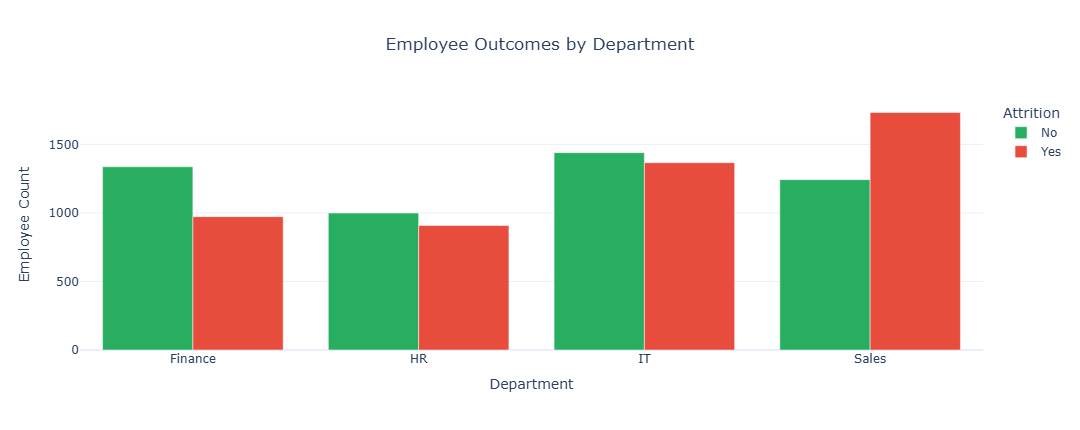

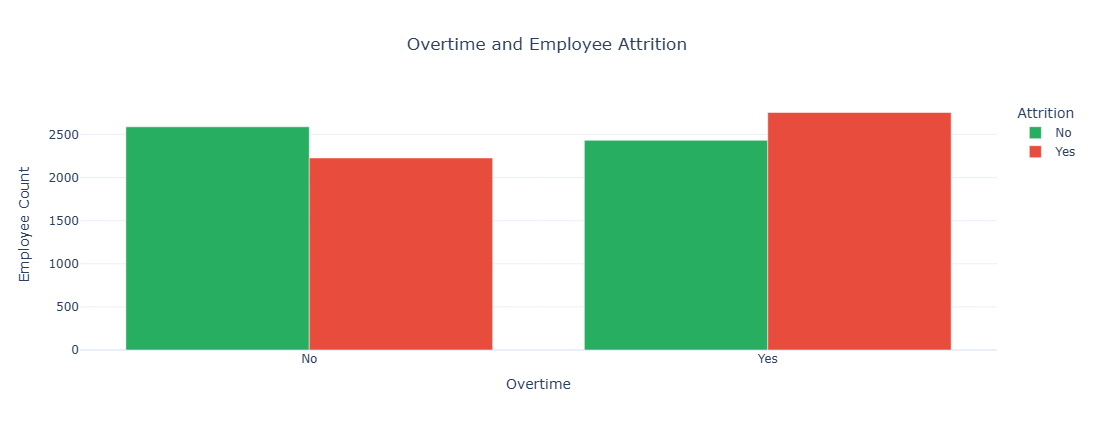


CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Stayed (No)       1.00      1.00      1.00      1004
  Left (Yes)       1.00      1.00      1.00       996

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



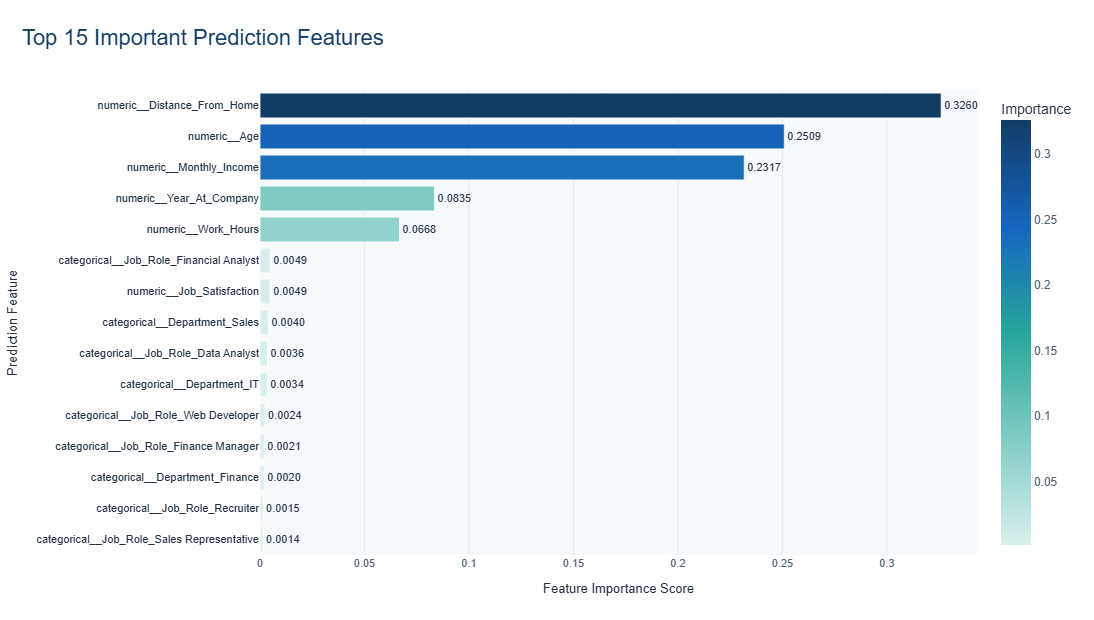

Model: Random Forest Classifier
Training records: 8000
Testing records: 2000


In [12]:

# ============================================================
# EMPLOYEE ATTRITION PREDICTION SYSTEM
# Machine Learning Dashboard using Random Forest
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import os
import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import ipywidgets as widgets

from IPython.display import display, HTML, clear_output

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

# ============================================================
# 1. ATTRACTIVE DASHBOARD DESIGN
# ============================================================

display(HTML("""
<style>
.main-title {
    background: linear-gradient(120deg,#101c3d,#2855a6,#4388d8);
    padding: 32px 20px;
    border-radius: 18px;
    text-align: center;
    color: white;
    margin-bottom: 22px;
    box-shadow: 0 8px 25px rgba(25,55,100,.2);
}
.main-title h1 {
    color: white;
    font-size: 30px;
    margin: 0;
}
.main-title p {
    color: #e2edff;
    font-size: 15px;
    margin-top: 12px;
}
.section-heading {
    background: #e8efff;
    color: #17365d;
    padding: 13px 18px;
    border-left: 6px solid #3974b8;
    border-radius: 8px;
    font-size: 21px;
    font-weight: bold;
    margin: 25px 0 15px 0;
}
.kpi-card {
    background: white;
    padding: 20px 12px;
    border-radius: 14px;
    text-align: center;
    border: 1px solid #e5eaf4;
    box-shadow: 0 5px 18px rgba(25,55,100,.10);
}
.kpi-card h4 {
    color: #52627d;
    margin-bottom: 12px;
}
.footer-box {
    background: linear-gradient(120deg,#101c3d,#2855a6);
    color: white;
    padding: 20px;
    border-radius: 12px;
    text-align: center;
    margin-top: 30px;
}
</style>
"""))

display(HTML("""
<div class="main-title">
    <h1>Employee Attrition Prediction System</h1>
    <p>Machine Learning Dashboard | Random Forest Classifier</p>
    <p>Employee Analytics • Performance Insights • Attrition Prediction</p>
</div>
"""))

# ============================================================
# 2. LOAD DATASET
# ============================================================

file_path =r"C:\Users\Swarda\Desktop\employee_attrition_cleaned.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Dataset not found. Please check the CSV file path."
    )

df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()
df = df.drop_duplicates().copy()

if "Attrition" not in df.columns:
    raise ValueError("Dataset must contain an Attrition column.")

df["Attrition"] = (
    df["Attrition"].astype(str).str.strip().str.title()
)
df = df[df["Attrition"].isin(["Yes", "No"])].copy()

if df.empty or df["Attrition"].nunique() != 2:
    raise ValueError(
        "Dataset must contain both Yes and No attrition values."
    )

# ============================================================
# 3. PREPARE FEATURES
# ============================================================

# Remove columns not used by the model
removed_columns = [
    "Attrition",
    "Employee_ID",
    "Performance_Rating",
    "Training_Hours",
    "Pervious_Compaines"
]

X = df.drop(columns=removed_columns, errors="ignore").copy()
y = df["Attrition"].map({"No": 0, "Yes": 1})

# Convert numeric-looking text columns to numeric
for col in X.columns:
    if X[col].dtype == "object":
        converted = pd.to_numeric(X[col], errors="coerce")
        non_missing = X[col].notna().sum()

        if non_missing > 0:
            if converted.notna().sum() / non_missing >= 0.8:
                X[col] = converted

numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# ============================================================
# 4. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ============================================================
# 5. DATA PREPROCESSING
# ============================================================

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# ============================================================
# 6. TRAIN RANDOM FOREST MODEL
# ============================================================

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

# ============================================================
# 7. MODEL EVALUATION
# ============================================================

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

roc_auc = (
    roc_auc_score(y_test, y_prob)
    if y_test.nunique() == 2 else np.nan
)

# ============================================================
# 8. EMPLOYEE OVERVIEW CARDS
# ============================================================

total_employees = len(df)
employees_left = int((df["Attrition"] == "Yes").sum())
employees_stayed = int((df["Attrition"] == "No").sum())
attrition_rate = employees_left / total_employees * 100

display(HTML("""
<div class="section-heading">Employee Overview</div>
"""))

display(HTML(f"""
<div style="
    display:grid;
    grid-template-columns:repeat(auto-fit,minmax(180px,1fr));
    gap:18px;">

    <div class="kpi-card" style="border-top:5px solid #3974b8;">
        <h4>Total Employees</h4>
        <h2 style="color:#3974b8;">{total_employees:,}</h2>
    </div>

    <div class="kpi-card" style="border-top:5px solid #e74c3c;">
        <h4> Employees Left</h4>
        <h2 style="color:#e74c3c;">{employees_left:,}</h2>
    </div>

    <div class="kpi-card" style="border-top:5px solid #27ae60;">
        <h4> Employees Stayed</h4>
        <h2 style="color:#27ae60;">{employees_stayed:,}</h2>
    </div>

    <div class="kpi-card" style="border-top:5px solid #e5a000;">
        <h4> Attrition Rate</h4>
        <h2 style="color:#d18b00;">{attrition_rate:.2f}%</h2>
    </div>

</div>
"""))

# ============================================================
# 9. ATTRITION DISTRIBUTION CHART
# ============================================================

display(HTML("""
<div class="section-heading"> Employee Attrition Distribution</div>
"""))

attrition_counts = (
    df["Attrition"].value_counts()
    .reindex(["Yes", "No"], fill_value=0)
    .rename_axis("Attrition")
    .reset_index(name="Employee Count")
)

fig = px.pie(
    attrition_counts,
    names="Attrition",
    values="Employee Count",
    hole=0.45,
    color="Attrition",
    color_discrete_map={
        "Yes": "#e74c3c",
        "No": "#27ae60"
    },
    title="Employees Who Left vs Stayed"
)

fig.update_layout(
    title_x=0.5,
    template="plotly_white",
    font=dict(family="Arial", size=14)
)
fig.show()

# ============================================================
# 10. ATTRITION BY DEPARTMENT
# ============================================================

if "Department" in df.columns:

    display(HTML("""
    <div class="section-heading"> Attrition by Department</div>
    """))

    department_data = (
        df.groupby(["Department", "Attrition"])
        .size()
        .reset_index(name="Employee Count")
    )

    fig = px.bar(
        department_data,
        x="Department",
        y="Employee Count",
        color="Attrition",
        barmode="group",
        color_discrete_map={
            "Yes": "#e74c3c",
            "No": "#27ae60"
        },
        title="Employee Outcomes by Department"
    )

    fig.update_layout(
        title_x=0.5,
        template="plotly_white",
        height=430
    )
    fig.show()

# ============================================================
# 11. ATTRITION BY OVERTIME
# ============================================================

if "Overtime" in df.columns:

    display(HTML("""
    <div class="section-heading"> Attrition by Overtime</div>
    """))

    overtime_data = (
        df.groupby(["Overtime", "Attrition"])
        .size()
        .reset_index(name="Employee Count")
    )

    fig = px.bar(
        overtime_data,
        x="Overtime",
        y="Employee Count",
        color="Attrition",
        barmode="group",
        color_discrete_map={
            "Yes": "#e74c3c",
            "No": "#27ae60"
        },
        title="Overtime and Employee Attrition"
    )

    fig.update_layout(
        title_x=0.5,
        template="plotly_white",
        height=430
    )
    fig.show()

# ============================================================
# 12. MODEL PERFORMANCE
# ============================================================

display(HTML("""
<div class="section-heading"> Random Forest Model Performance</div>
<p style="color:#66758f;">
Evaluation metrics calculated on the test dataset.
</p>
"""))

display(HTML(f"""
<div style="
    display:grid;
    grid-template-columns:repeat(auto-fit,minmax(140px,1fr));
    gap:15px;">

    <div class="kpi-card" style="border-top:5px solid #3974b8;">
        <h4>Accuracy</h4>
        <h2>{accuracy:.3f}</h2>
    </div>

    <div class="kpi-card" style="border-top:5px solid #27ae60;">
        <h4>Precision</h4>
        <h2>{precision:.3f}</h2>
    </div>

    <div class="kpi-card" style="border-top:5px solid #e5a000;">
        <h4>Recall</h4>
        <h2>{recall:.3f}</h2>
    </div>

    <div class="kpi-card" style="border-top:5px solid #8e63c7;">
        <h4>F1 Score</h4>
        <h2>{f1:.3f}</h2>
    </div>

    <div class="kpi-card" style="border-top:5px solid #e74c3c;">
        <h4>ROC-AUC</h4>
        <h2>{roc_auc:.3f}</h2>
    </div>

</div>
"""))

print("\nCLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Stayed (No)", "Left (Yes)"],
    zero_division=0
))

# ============================================================
# 13. FEATURE IMPORTANCE
# ============================================================

display(HTML("""
<div class="section-heading"> Important Prediction Features</div>
"""))

feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = model.named_steps["classifier"].feature_importances_

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Select the top 15 important features
top_features = (
    feature_importance
    .sort_values(by="Importance", ascending=False)
    .head(15)
    .sort_values(by="Importance", ascending=True)
)

# Create the chart with a professional white theme
fig = px.bar(
    top_features,
    x="Importance",
    y="Feature",
    orientation="h",
    color="Importance",
    color_continuous_scale=[
        "#D9F0EE",  # Light teal
        "#80CBC4",  # Soft teal
        "#26A69A",  # Teal
        "#1565C0",  # Blue
        "#123B63"   # Deep blue
    ],
    title="Top 15 Important Prediction Features",
    labels={
        "Importance": "Feature Importance Score",
        "Feature": "Prediction Feature"
    },
    text=top_features["Importance"].apply(lambda x: f"{x:.4f}")
)

# Customize bar appearance and labels
fig.update_traces(
    textposition="outside",
    textfont=dict(
        family="Arial",
        size=11,
        color="#243447"
    ),
    marker_line_color="#FFFFFF",
    marker_line_width=0.8,
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Importance Score: %{x:.4f}"
        "<extra></extra>"
    ),
    cliponaxis=False
)

# Customize the complete chart layout
fig.update_layout(
    template="plotly_white",

    title=dict(
        text="Top 15 Important Prediction Features",
        font=dict(
            family="Arial",
            size=22,
            color="#123B63"
        ),
        x=0.02,
        xanchor="left"
    ),

    paper_bgcolor="#FFFFFF",
    plot_bgcolor="#F7FAFC",

    font=dict(
        family="Arial",
        size=12,
        color="#243447"
    ),

    xaxis=dict(
        title="Feature Importance Score",
        title_font=dict(size=13, color="#243447"),
        tickfont=dict(size=11, color="#526477"),
        showgrid=True,
        gridcolor="#E3EAF0",
        zeroline=False
    ),

    yaxis=dict(
        title="Prediction Feature",
        title_font=dict(size=13, color="#243447"),
        tickfont=dict(size=11, color="#243447"),
        showgrid=False,
        automargin=True
    ),

    coloraxis_colorbar=dict(
        title=dict(
            text="Importance",
            font=dict(color="#243447")
        ),
        tickfont=dict(color="#526477"),
        outlinewidth=0
    ),

    margin=dict(
        l=25,
        r=75,
        t=90,
        b=65
    ),

    height=620,

    hoverlabel=dict(
        bgcolor="#FFFFFF",
        bordercolor="#26A69A",
        font=dict(color="#243447", size=12)
    )
)

# Display the final chart
fig.show()
# ============================================================

# ============================================================
# 15. SAVE MODEL
# ============================================================

joblib.dump(model, "employee_attrition_random_forest.joblib")

display(HTML("""
<div style="
    background:#e5f8ec;
    padding:18px;
    border-radius:12px;
    margin-top:25px;
    color:#176b3a;">
</div>

<div class="footer-box">
    <h3 style="color:white;">Employee Attrition Prediction System</h3>
    <p>Python • Pandas • Plotly • Scikit-learn</p>
    <p>Random Forest Classification | Thank You!</p>
</div>
"""))

print("Model: Random Forest Classifier")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
